# YallaLayer — Exploratory Data Analysis

## 1. Introduction

This notebook explores the Online Shoppers Purchasing Intention Dataset.

### Objectives
- Understand the dataset structure.
- Study the features and their characteristics.
- Identify patterns related to purchasing behavior.
- Explore relationships between variables.
- Document findings to guide data preparation and model development.

## 2. Dataset Information

- Source: UCI Machine Learning Repository
- Dataset: Online Shoppers Purchasing Intention
- Task: Supervised Binary Classification
- Target: Revenue
- Exploration Data: Training Set Only

In [2]:
import sys

print("Python executable:")
print(sys.executable)

Python executable:
c:\Projects\YallaLayer\.venv\Scripts\python.exe


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)

In [4]:
DATA_PATH = Path("../data/exploration/train_exploration.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (9864, 18)


In [5]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,4,1,9,3,Returning_Visitor,False,False
2,0,0.000,0,0.000,2,2.667,0.050,0.140,0.000,0.000,Feb,3,2,2,4,Returning_Visitor,False,False
3,0,0.000,0,0.000,10,627.500,0.020,0.050,0.000,0.000,Feb,3,3,1,4,Returning_Visitor,True,False
4,1,0.000,0,0.000,0,0.000,0.200,0.200,0.000,0.000,Feb,1,2,1,5,Returning_Visitor,True,False


In [6]:
df.sample(5, random_state=42)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
9746,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Dec,8,13,9,20,Other,False,False
500,0,0.000,0,0.000,7,383.500,0.000,0.024,0.000,0.000,Mar,3,2,6,3,Returning_Visitor,False,False
4852,0,0.000,1,0.000,14,331.550,0.013,0.018,0.000,0.000,June,1,1,1,2,Returning_Visitor,True,False
872,0,0.000,0,0.000,19,606.833,0.032,0.048,0.000,0.000,Mar,2,2,1,3,Returning_Visitor,False,False
6202,0,0.000,0,0.000,18,1110.867,0.000,0.015,57.035,0.000,Aug,2,10,4,1,Returning_Visitor,False,True


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9864 entries, 0 to 9863
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           9864 non-null   int64  
 1   Administrative_Duration  9864 non-null   float64
 2   Informational            9864 non-null   int64  
 3   Informational_Duration   9864 non-null   float64
 4   ProductRelated           9864 non-null   int64  
 5   ProductRelated_Duration  9864 non-null   float64
 6   BounceRates              9864 non-null   float64
 7   ExitRates                9864 non-null   float64
 8   PageValues               9864 non-null   float64
 9   SpecialDay               9864 non-null   float64
 10  Month                    9864 non-null   str    
 11  OperatingSystems         9864 non-null   int64  
 12  Browser                  9864 non-null   int64  
 13  Region                   9864 non-null   int64  
 14  TrafficType              9864 non-n

In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,9864.000,NaN,NaN,NaN,2.329,3.318,0.000,0.000,1.000,4.000,26.000
Administrative_Duration,9864.000,NaN,NaN,NaN,81.706,177.742,0.000,0.000,9.000,94.733,3398.750
Informational,9864.000,NaN,NaN,NaN,0.507,1.296,0.000,0.000,0.000,0.000,24.000
Informational_Duration,9864.000,NaN,NaN,NaN,35.342,146.527,0.000,0.000,0.000,0.000,2549.375
ProductRelated,9864.000,NaN,NaN,NaN,31.997,45.206,0.000,7.000,18.000,38.000,705.000
ProductRelated_Duration,9864.000,NaN,NaN,NaN,1203.072,1960.284,0.000,184.000,601.778,1472.333,63973.522
BounceRates,9864.000,NaN,NaN,NaN,0.022,0.048,0.000,0.000,0.003,0.017,0.200
ExitRates,9864.000,NaN,NaN,NaN,0.043,0.049,0.000,0.014,0.025,0.050,0.200
PageValues,9864.000,NaN,NaN,NaN,5.894,18.629,0.000,0.000,0.000,0.000,361.764
SpecialDay,9864.000,NaN,NaN,NaN,0.061,0.200,0.000,0.000,0.000,0.000,1.000


In [9]:


missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100)
})

missing_values = missing_values.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_values)


duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)
print(
    "Duplicate percentage:",
    round((duplicate_count / len(df)) * 100, 2),
    "%"
)

,Missing Count,Missing Percentage
Administrative,0,0.000
Administrative_Duration,0,0.000
Informational,0,0.000
Informational_Duration,0,0.000
ProductRelated,0,0.000
ProductRelated_Duration,0,0.000
BounceRates,0,0.000
ExitRates,0,0.000
PageValues,0,0.000
SpecialDay,0,0.000


Duplicate rows: 98
Duplicate percentage: 0.99 %


In [10]:

target_counts = df["Revenue"].value_counts()

target_percentages = df["Revenue"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary)

,Count,Percentage
Revenue,,
False,8338,84.530
True,1526,15.470


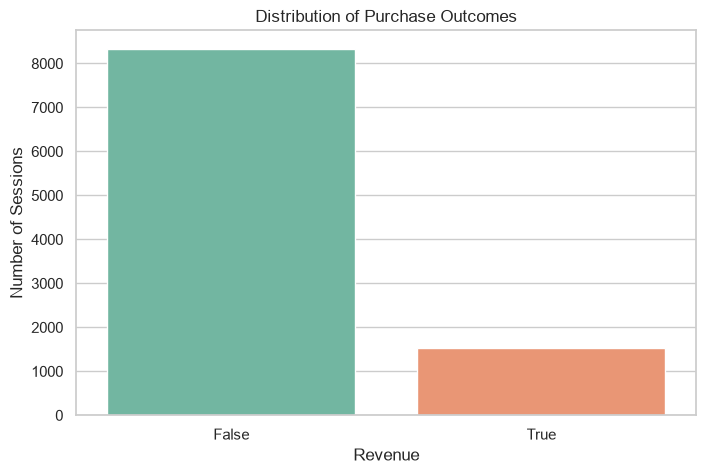

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Revenue",
    hue="Revenue",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Purchase Outcomes")
plt.xlabel("Revenue")
plt.ylabel("Number of Sessions")

plt.show()

In [12]:
categorical_features = [
    "Month",
    "VisitorType",
    "Weekend"
]

for col in categorical_features:

    print(f"\n{'='*50}")
    print(f"Feature: {col}")
    print("="*50)

    summary = pd.DataFrame({
        "Count": df[col].value_counts(),
        "Percentage": df[col].value_counts(normalize=True) * 100
    })

    display(summary)


Feature: Month


,Count,Percentage
Month,,
May,2660,26.967
Nov,2424,24.574
Mar,1504,15.247
Dec,1404,14.234
Oct,436,4.420
Sep,366,3.710
Jul,344,3.487
Aug,342,3.467
June,237,2.403



Feature: VisitorType


,Count,Percentage
VisitorType,,
Returning_Visitor,8427,85.432
New_Visitor,1367,13.858
Other,70,0.710



Feature: Weekend


,Count,Percentage
Weekend,,
False,7583,76.876
True,2281,23.124


In [13]:
coded_categorical_features = [
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

for col in coded_categorical_features:

    print(f"\n{'='*50}")
    print(f"Feature: {col}")
    print("="*50)

    summary = pd.DataFrame({
        "Count": df[col].value_counts().sort_index(),
        "Percentage": (
            df[col].value_counts(normalize=True).sort_index() * 100
        )
    })

    display(summary)


Feature: OperatingSystems


,Count,Percentage
OperatingSystems,,
1,2076,21.046
2,5256,53.285
3,2055,20.833
4,387,3.923
5,3,0.030
6,17,0.172
7,4,0.041
8,66,0.669



Feature: Browser


,Count,Percentage
Browser,,
1,1978,20.053
2,6362,64.497
3,85,0.862
4,582,5.900
5,368,3.731
6,142,1.440
7,37,0.375
8,109,1.105
10,138,1.399



Feature: Region


,Count,Percentage
Region,,
1,3813,38.656
2,914,9.266
3,1919,19.455
4,947,9.601
5,252,2.555
6,637,6.458
7,606,6.144
8,352,3.569
9,424,4.298



Feature: TrafficType


,Count,Percentage
TrafficType,,
1,1970,19.972
2,3100,31.427
3,1648,16.707
4,865,8.769
5,196,1.987
6,353,3.579
7,33,0.335
8,286,2.899
9,32,0.324


In [14]:
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

numerical_summary = pd.DataFrame({
    "Mean": df[numerical_features].mean(),
    "Median": df[numerical_features].median(),
    "Std": df[numerical_features].std(),
    "Min": df[numerical_features].min(),
    "Max": df[numerical_features].max(),
    "Skewness": df[numerical_features].skew(),
    "Zero_Percentage": (
        (df[numerical_features] == 0).mean() * 100
    )
})

display(numerical_summary.round(3))

,Mean,Median,Std,Min,Max,Skewness,Zero_Percentage
Administrative,2.329,1.000,3.318,0.000,26.000,1.905,46.543
Administrative_Duration,81.706,9.000,177.742,0.000,3398.750,5.601,47.577
Informational,0.507,0.000,1.296,0.000,24.000,4.160,78.842
Informational_Duration,35.342,0.000,146.527,0.000,2549.375,7.643,80.728
ProductRelated,31.997,18.000,45.206,0.000,705.000,4.400,0.324
ProductRelated_Duration,1203.072,601.778,1960.284,0.000,63973.522,7.770,6.062
BounceRates,0.022,0.003,0.048,0.000,0.200,2.963,44.728
ExitRates,0.043,0.025,0.049,0.000,0.200,2.148,0.669
PageValues,5.894,0.000,18.629,0.000,361.764,6.351,77.910
SpecialDay,0.061,0.000,0.200,0.000,1.000,3.308,89.893


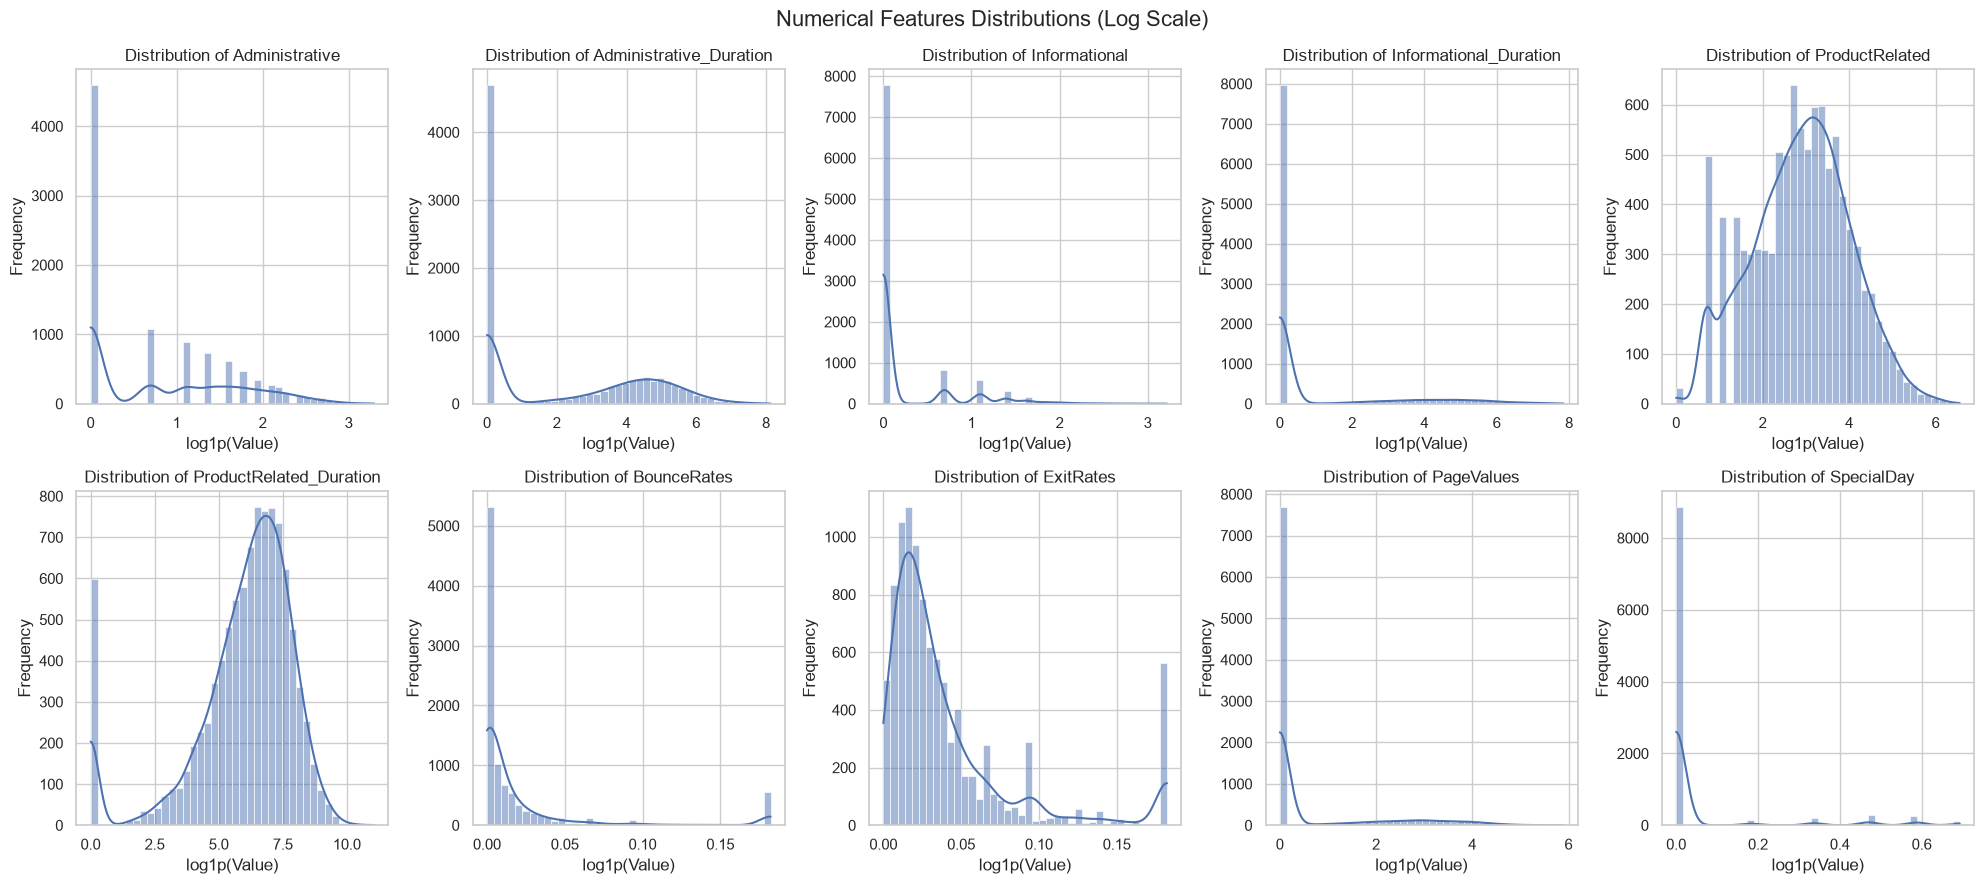

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(20, 9))

for ax, col in zip(axes.flatten(), numerical_features):

    values = np.log1p(df[col])

    sns.histplot(
        values,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("log1p(Value)")
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Numerical Features Distributions (Log Scale)",
    fontsize=16
)

plt.tight_layout()
plt.show()

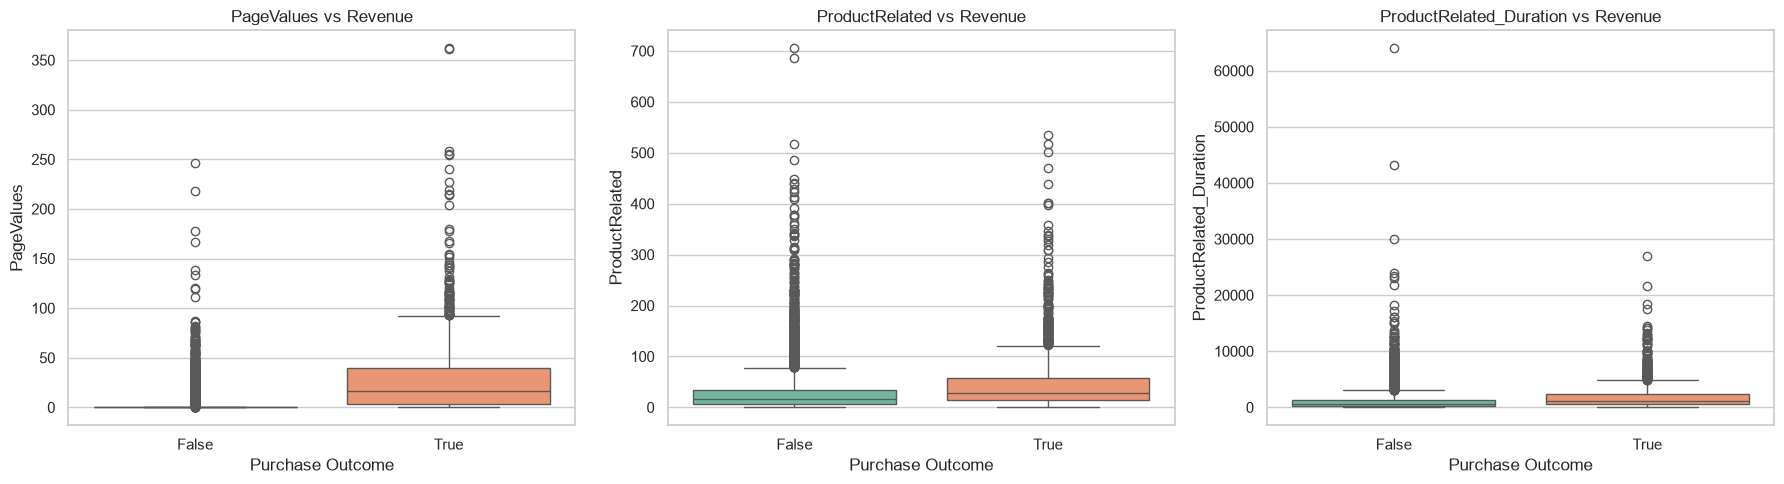

In [16]:
important_features = [
    "PageValues",
    "ProductRelated",
    "ProductRelated_Duration"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, important_features):

    sns.boxplot(
        data=df,
        x="Revenue",
        y=feature,
        hue="Revenue",
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(f"{feature} vs Revenue")
    ax.set_xlabel("Purchase Outcome")

plt.tight_layout()
plt.show()

In [17]:
features_to_compare = [
    "PageValues",
    "ProductRelated",
    "ProductRelated_Duration"
]

comparison = df.groupby("Revenue")[features_to_compare].agg(
    ["mean", "median", "std", "min", "max"]
)

display(comparison.round(3))

PageValues                             ProductRelated                \
              mean median    std   min     max           mean median    std   
Revenue                                                                       
False        1.942  0.000  9.063 0.000 246.759         28.861 16.000 41.173   
True        27.491 16.509 35.260 0.000 361.764         49.129 29.000 60.017   

                 ProductRelated_Duration                                    
        min  max                    mean   median      std   min       max  
Revenue                                                                     
False     0  705                1075.099  513.031 1852.750 0.000 63973.522  
True      0  534                1902.311 1133.736 2346.918 0.000 27009.859

In [18]:
# Numerical feature correlation with target

correlation_df = df[numerical_features].copy()
correlation_df["Revenue"] = df["Revenue"].astype(int)

target_correlation = (
    correlation_df.corr()["Revenue"]
    .drop("Revenue")
    .sort_values(key=abs, ascending=False)
)

display(target_correlation.to_frame("Correlation with Revenue").round(3))

,Correlation with Revenue
PageValues,0.496
ExitRates,-0.208
ProductRelated,0.162
ProductRelated_Duration,0.153
BounceRates,-0.150
Administrative,0.142
Administrative_Duration,0.098
Informational,0.089
SpecialDay,-0.081
Informational_Duration,0.062


In [19]:
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

outlier_results = []

for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_results.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(df) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df.sort_values(
    "Outlier Percentage",
    ascending=False
).round(2)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
8,PageValues,0.000,0.000,2179,22.090
2,Informational,0.000,0.000,2087,21.160
3,Informational_Duration,0.000,0.000,1901,19.270
6,BounceRates,-0.030,0.040,1238,12.550
9,SpecialDay,0.000,0.000,997,10.110
1,Administrative_Duration,-142.100,236.830,928,9.410
7,ExitRates,-0.040,0.100,875,8.870
4,ProductRelated,-39.500,84.500,796,8.070
5,ProductRelated_Duration,-1748.500,3404.830,771,7.820
0,Administrative,-6.000,10.000,331,3.360


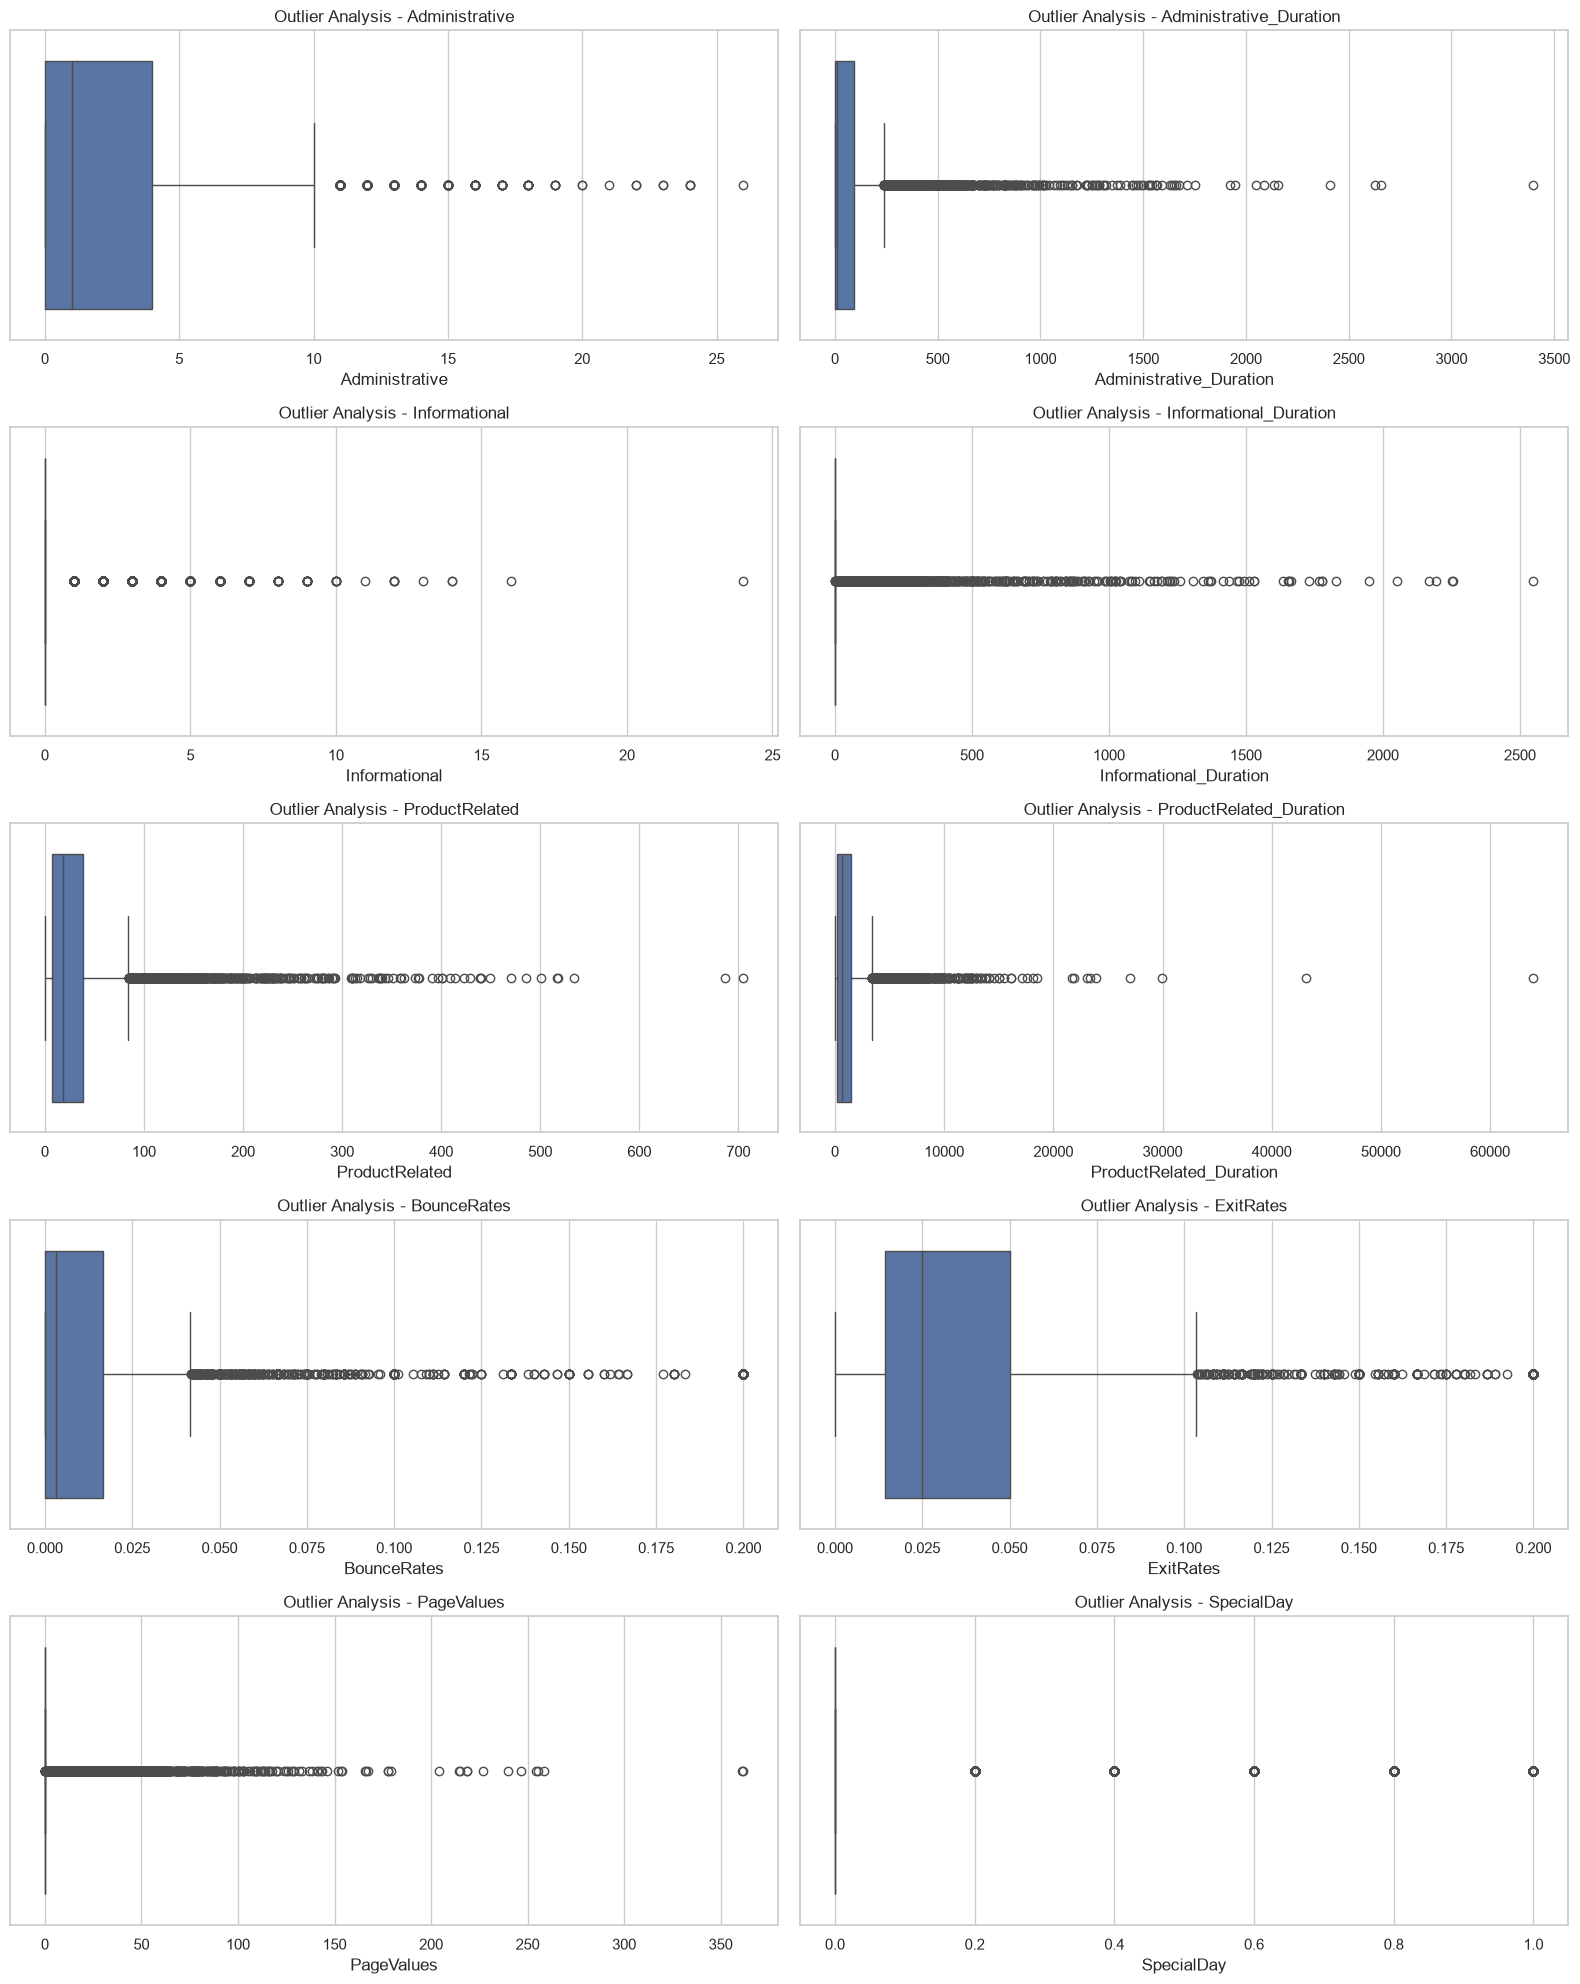

In [20]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(16, 20)
)

for ax, col in zip(axes.flatten(), numerical_features):
    sns.boxplot(
        data=df,
        x=col,
        ax=ax
    )

    ax.set_title(f"Outlier Analysis - {col}")

plt.tight_layout()
plt.show()

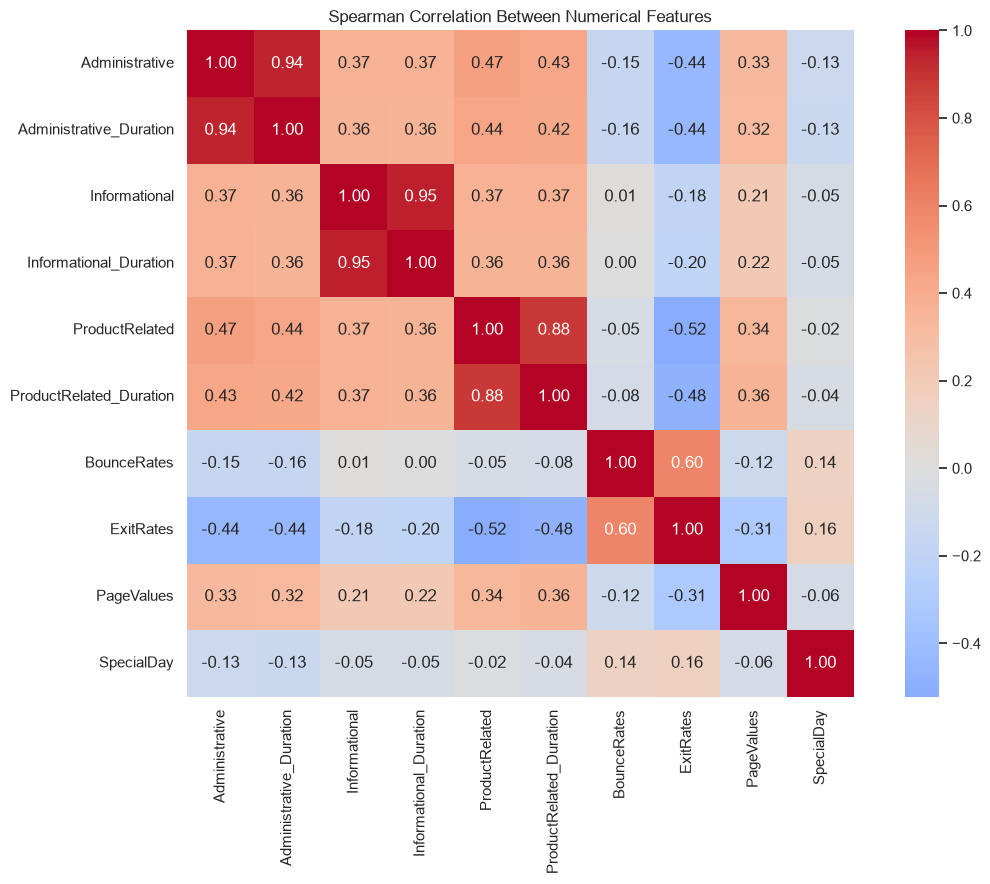

In [21]:
correlation_matrix = df[numerical_features].corr(
    method="spearman"
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Spearman Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [23]:
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

high_correlations = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlations.columns = [
    "Feature 1",
    "Feature 2",
    "Spearman Correlation"
]

high_correlations["Absolute Correlation"] = (
    high_correlations["Spearman Correlation"].abs()
)

high_correlations = high_correlations[
    high_correlations["Absolute Correlation"] >= 0.70
].sort_values(
    "Absolute Correlation",
    ascending=False
)

high_correlations.round(3)

,Feature 1,Feature 2,Spearman Correlation,Absolute Correlation
23,Informational,Informational_Duration,0.950,0.950
1,Administrative,Administrative_Duration,0.940,0.940
45,ProductRelated,ProductRelated_Duration,0.883,0.883


In [29]:
from scipy.stats import mannwhitneyu

numerical_test_results = []

buyers = df[df["Revenue"] == True]
non_buyers = df[df["Revenue"] == False]

for col in numerical_features:

    x = buyers[col].dropna()
    y = non_buyers[col].dropna()

    statistic, p_value = mannwhitneyu(
        x,
        y,
        alternative="two-sided"
    )

    # Rank-biserial correlation effect size
    effect_size = (
        2 * statistic / (len(x) * len(y))
    ) - 1

    numerical_test_results.append({
        "Feature": col,
        "Buyer Median": x.median(),
        "Non-Buyer Median": y.median(),
        "U Statistic": statistic,
        "P-value": p_value,
        "Rank-Biserial Effect": effect_size
    })

numerical_tests = pd.DataFrame(
    numerical_test_results
)

numerical_tests

,Feature,Buyer Median,Non-Buyer Median,U Statistic,P-value,Rank-Biserial Effect
0,Administrative,2.000,0.000,8014802.000,0.000,0.260
1,Administrative_Duration,55.000,0.000,7997157.500,0.000,0.257
2,Informational,0.000,0.000,7153684.500,0.000,0.124
3,Informational_Duration,0.000,0.000,7123262.500,0.000,0.120
4,ProductRelated,29.000,16.000,8397248.500,0.000,0.320
5,ProductRelated_Duration,1133.736,513.031,8602981.500,0.000,0.352
6,BounceRates,0.000,0.004,4897444.500,0.000,-0.230
7,ExitRates,0.016,0.029,3729444.000,0.000,-0.414
8,PageValues,16.509,0.000,11019541.000,0.000,0.732
9,SpecialDay,0.000,0.000,5917688.000,0.000,-0.070


In [31]:
from scipy.stats import mannwhitneyu, chi2_contingency

categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

categorical_test_results = []

for col in categorical_features:

    contingency_table = pd.crosstab(
        df[col],
        df["Revenue"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()
    rows, cols = contingency_table.shape

    # Bias-corrected Cramer's V
    phi2 = chi2 / n

    phi2_corrected = max(
        0,
        phi2 - ((cols - 1) * (rows - 1)) / (n - 1)
    )

    rows_corrected = rows - (
        (rows - 1) ** 2 / (n - 1)
    )

    cols_corrected = cols - (
        (cols - 1) ** 2 / (n - 1)
    )

    denominator = min(
        cols_corrected - 1,
        rows_corrected - 1
    )

    cramers_v = (
        np.sqrt(phi2_corrected / denominator)
        if denominator > 0 else np.nan
    )

    categorical_test_results.append({
        "Feature": col,
        "Chi-Square": chi2,
        "Degrees of Freedom": dof,
        "P-value": p_value,
        "Cramer's V": cramers_v,
        "Min Expected Frequency": expected.min(),
        "Expected Cells Below 5 (%)": (
            (expected < 5).sum() / expected.size * 100
        )
    })

categorical_tests = pd.DataFrame(
    categorical_test_results
)

categorical_tests.round(4)

,Feature,Chi-Square,Degrees of Freedom,P-value,Cramer's V,Min Expected Frequency,Expected Cells Below 5 (%)
0,Month,319.478,9,0.000,0.177,22.741,0.000
1,OperatingSystems,63.317,7,0.000,0.076,0.464,31.250
2,Browser,27.319,11,0.004,0.041,0.464,12.500
3,Region,6.551,8,0.586,0.000,38.985,0.000
4,TrafficType,293.550,19,0.000,0.167,0.155,27.500
5,VisitorType,109.233,2,0.000,0.104,10.829,0.000
6,Weekend,10.309,1,0.001,0.031,352.880,0.000


In [ ]:
from statsmodels.stats.multitest import multipletests

all_tests = pd.concat([
    numerical_tests[["Feature", "P-value"]].assign(
        Test_Type="Mann-Whitney U"
    ),
    categorical_tests[["Feature", "P-value"]].assign(
        Test_Type="Chi-Square"
    )
], ignore_index=True)



    all_tests = pd.concat([
        numerical_tests[["Feature", "P-value"]].assign(
            Test_Type="Mann-Whitney U"
        ),
        categorical_tests[["Feature", "P-value"]].assign(
            Test_Type="Chi-Square"
        )
    ], ignore_index=True)

    reject, adjusted_p_values, _, _ = multipletests(
        all_tests["P-value"],
        method="fdr_bh"
    )

    all_tests["Adjusted P-value"] = adjusted_p_values
    all_tests["Significant"] = reject

    all_tests.sort_values("Adjusted P-value").round(5)
)

all_tests["Adjusted P-value"] = adjusted_p_values
all_tests["Significant"] = reject

all_tests.sort_values(
    "Adjusted P-value"
).round(5)

IndentationError: unexpected indent (2874154642.py, line 14)

In [34]:
page_values_summary = df.groupby("Revenue")[
    "PageValues"
].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

page_values_summary


,count,mean,median,std,min,max
Revenue,,,,,,
False,8338,1.942,0.000,9.063,0.000,246.759
True,1526,27.491,16.509,35.260,0.000,361.764


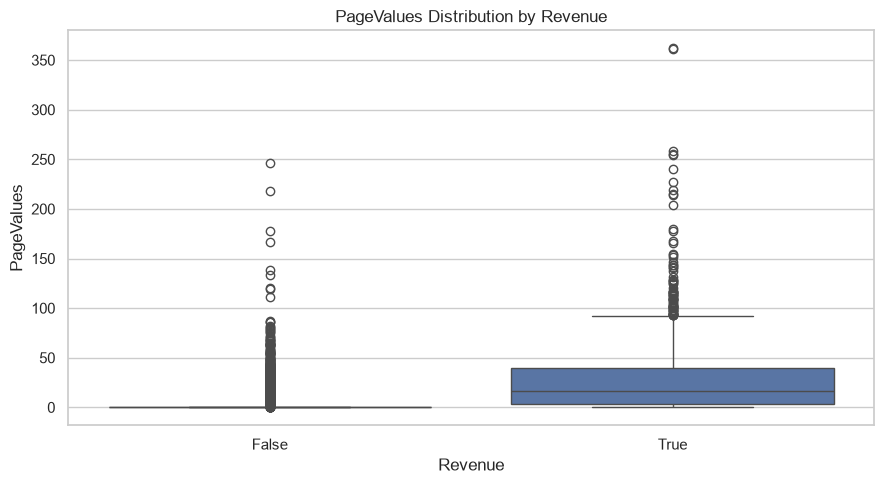

In [35]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Revenue",
    y="PageValues"
)

plt.title("PageValues Distribution by Revenue")
plt.xlabel("Revenue")
plt.ylabel("PageValues")

plt.tight_layout()
plt.show()